# S&P 500 Diversification Challenge — Find the Best Diversifying Pair

You are a portfolio analyst at an investment fund. Your task is to identify two stocks from the S&P 500 that, when combined in an equally weighted portfolio, provide the **largest and most stable diversification benefit**.

You will solve two problems: first, without any return requirement, and then with a minimum return constraint.

## Your objective

Find the eligible pair of stocks with the **highest diversification score** over **January 2, 2024 to December 31, 2025**, inclusive, using daily Adjusted Close prices adjusted for stock splits and dividends.

Each portfolio must contain two different stocks with fixed weights:

$$
w_1=w_2=0.5
$$

## Eligible stocks and data

Use the **fixed S&P 500 component list from Wikipedia's snapshot downloaded October 7, 2026**. The list must be supplied as a CSV file named `sp500_components_2026-10-07.csv`, with a `Symbol` column. Do not replace the snapshot with Wikipedia's current live membership: later changes are irrelevant.

Use the same stock universe and analysis period as in the previous Tail Risk Challenge.

The following rules apply:

- Download daily **Adjusted Close** prices and calculate daily log returns.
- A stock must have valid daily returns for at least **90% of US equity trading sessions** in the analysis period.

$$
r_{P,t}=0.5r_{1,t}+0.5r_{2,t}
$$


- Use **63-day rolling windows** containing complete daily return observations.
- Use sample standard deviations (`ddof=1`) for volatility and for the variability of diversification gains.


## 1. Calculate the diversification gain

For each eligible pair of stocks, calculate the diversification gain in each rolling window:

$$
DG_t=1-\frac{\sigma_{P,t}}{0.5\sigma_{1,t}+0.5\sigma_{2,t}}
$$

where:

- $\sigma_{P,t}$ is the volatility of the 50%-50% portfolio.
- $\sigma_{1,t}$ and $\sigma_{2,t}$ are the individual stock volatilities.

All volatilities must be calculated using daily log returns over the same 63-day window.

The denominator represents the portfolio volatility that would arise if the stocks were perfectly positively correlated.

Next, calculate:

$$
Score=\operatorname{Mean}(DG)-0.5\operatorname{SD}(DG)
$$

The score rewards a high average diversification gain and penalizes instability.

**Higher scores are better.**

Also calculate the minimum diversification gain observed across the rolling windows.

## 2. Part A — Without a return constraint

Find the eligible pair of stocks that achieves the **highest diversification score**, regardless of its mean return.

Calculate the pair's annualized mean portfolio log return:

$$
\bar r_{P,ann}=252\operatorname{Mean}(r_{P,daily})
$$

## 3. Part B — With a return constraint

Repeat the search, but now consider only pairs whose annualized mean log return is at least as high as that of the S&P 500 index over the same period.

The condition is:

$$
\bar r_{P,ann}\geq\bar r_{S\&P500,ann}
$$

Use `^GSPC` as the S&P 500 benchmark.

Both annualized mean log returns must be calculated using the same dates and the same methodology:

$$
\bar r_{ann}=252\operatorname{Mean}(r_{daily})
$$

Among all eligible pairs satisfying the return constraint, select the one with the **highest diversification score**.

## 4. What to submit

For **each part**, report:

1. The two selected tickers, in alphabetical order, using the original Wikipedia symbols.
2. The annualized mean portfolio return (%).
3. The mean rolling diversification gain (%).
4. The standard deviation of the rolling diversification gain (%).
5. The minimum rolling diversification gain (%).
6. The final diversification score (%).

Plot both selected pairs' rolling diversification-gain series in the same figure.

Answer the following questions:

1. Did the return constraint change the selected pair?
2. Did the highest attainable diversification score decrease? Why?
3. Which selected pair has the more stable diversification gain?
4. Why is selecting the pair with the lowest full-sample correlation not necessarily equivalent to maximizing the diversification score?

**Important:** Briefly explain your selection method, how you aligned trading dates, how you handled missing observations, and how you calculated the rolling statistics. Brute-force search is allowed.

## 5. Financial interpretation

The challenge illustrates that diversification depends on more than simply choosing two stocks with low correlation.

A good pair should provide a **large and stable reduction in portfolio volatility**. Imposing a minimum return requirement may also change which pairs are attractive.

The diversification score measures historical risk reduction relative to a hypothetical perfectly correlated portfolio. It does not guarantee that the same diversification benefit will persist in the future.

### Data and reproducibility

Upload `sp500_components_2026-10-07.csv` containing the frozen universe (`Symbol` column) to the same folder as the notebook, or update `SNAPSHOT_CSV` to its location. The solution fetches prices from Yahoo Finance; rerunning at a later date can return revised historical data. To reproduce official rankings exactly, use the instructor's frozen reference prices as well.

The benchmark is evaluated on the same available daily return dates as each pair. Rolling 63-day windows retain the complete reference trading calendar, and missing observations invalidate that window.

## Solution 1 — Set up the analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from itertools import combinations
from tqdm import tqdm
import requests
from io import StringIO

START_DATE = "2024-01-02"
END_DATE = "2026-01-01"  # Exclusive
WINDOW = 63
SNAPSHOT_CSV = "sp500_components_2026-10-07.csv"


## Solution 2 — Load the fixed stock universe

In [2]:
# Download the S&P 500 component table.
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
response.raise_for_status()

# Preserve Wikipedia symbols and adapt them for Yahoo Finance.
wikipedia_tickers = pd.read_html(StringIO(response.text))[0]["Symbol"].tolist()
sp500_tickers = [ticker.replace(".", "-") for ticker in wikipedia_tickers]

sp500_tickers

['MMM',
 'AOS',
 'ABT',
 'ABBV',
 'ACN',
 'ADBE',
 'AMD',
 'AES',
 'AFL',
 'A',
 'APD',
 'ABNB',
 'AKAM',
 'ALB',
 'ARE',
 'ALGN',
 'ALLE',
 'LNT',
 'ALL',
 'GOOGL',
 'GOOG',
 'MO',
 'AMZN',
 'AMCR',
 'AEE',
 'AEP',
 'AXP',
 'AIG',
 'AMT',
 'AWK',
 'AMP',
 'AME',
 'AMGN',
 'APH',
 'ADI',
 'AON',
 'APA',
 'APO',
 'AAPL',
 'AMAT',
 'APP',
 'APTV',
 'ACGL',
 'ADM',
 'ARES',
 'ANET',
 'AJG',
 'AIZ',
 'T',
 'ATO',
 'ADSK',
 'ADP',
 'AZO',
 'AVY',
 'AXON',
 'BKR',
 'BALL',
 'BAC',
 'BAX',
 'BDX',
 'BRK-B',
 'BBY',
 'TECH',
 'BIIB',
 'BLK',
 'BX',
 'XYZ',
 'BE',
 'BNY',
 'BA',
 'BKNG',
 'BSX',
 'BMY',
 'AVGO',
 'BR',
 'BRO',
 'BF-B',
 'BG',
 'BXP',
 'CHRW',
 'CDNS',
 'CPT',
 'COF',
 'CAH',
 'CCL',
 'CARR',
 'CVNA',
 'CASY',
 'CAT',
 'CBOE',
 'CBRE',
 'CDW',
 'COR',
 'CNC',
 'CNP',
 'CF',
 'CRL',
 'SCHW',
 'CHTR',
 'CVX',
 'CMG',
 'CB',
 'CHD',
 'CIEN',
 'CI',
 'CINF',
 'CTAS',
 'CSCO',
 'C',
 'CFG',
 'CLX',
 'CME',
 'CMS',
 'KO',
 'CTSH',
 'COHR',
 'COIN',
 'CL',
 'CMCSA',
 'FIX',
 'COP',
 'E

## Solution 3 — Download benchmark returns and define trading sessions

In [3]:
# Include the previous trading day to calculate the first return of 2024.
benchmark_prices = yf.download(
    "^GSPC", start="2023-12-28", end=END_DATE,
    auto_adjust=False, multi_level_index=False, progress=False,
)["Adj Close"]
sp500_returns = np.log(benchmark_prices / benchmark_prices.shift(1))
sp500_returns = sp500_returns.loc[START_DATE:"2025-12-31"].dropna()
dates = sp500_returns.index
print(f"Benchmark sessions: {len(dates)}")

Benchmark sessions: 502


## Solution 4 — Calculate eligible stock returns

In [4]:
# Download stock prices, compute returns first, then align to the benchmark calendar.
prices = yf.download(
    sp500_tickers, start="2023-12-28", end=END_DATE,
    auto_adjust=False, progress=False,
)["Adj Close"]
log_returns = np.log(prices / prices.shift(1)).reindex(dates)
log_returns = log_returns.loc[:, log_returns.notna().mean() >= 0.90]
print(f"Eligible stocks: {log_returns.shape[1]}")

$HONA: Data doesn't exist for startDate = 1703739600, endDate = 1767243600
$FDXF: Data doesn't exist for startDate = 1703739600, endDate = 1767243600
$VYLR: Data doesn't exist for startDate = 1703739600, endDate = 1767243600

3 Failed downloads:
['HONA', 'FDXF', 'VYLR']: Data doesn't exist for startDate = 1703739600, endDate = 1767243600


Eligible stocks: 495


## Solution 5 — Search and score every pair

In [5]:
# Evaluate every distinct pair without deleting missing dates before rolling.
results = []
n = log_returns.shape[1]
pairs = combinations(log_returns.columns, 2)

for stock1, stock2 in tqdm(pairs, total=n * (n - 1) // 2, desc="Evaluating pairs"):
    r1, r2 = log_returns[stock1], log_returns[stock2]
    portfolio = (r1 + r2) / 2

    # Missing observations make a complete 63-session rolling window invalid.
    sd1 = r1.rolling(WINDOW).std()
    sd2 = r2.rolling(WINDOW).std()
    sdp = portfolio.rolling(WINDOW).std()
    dg = (1 - sdp / ((sd1 + sd2) / 2)).replace([np.inf, -np.inf], np.nan).dropna()
    if len(dg) < 2:
        continue

    common_dates = portfolio.dropna().index
    mean_dg = dg.mean()
    sd_dg = dg.std()
    results.append({
        "Stock 1": stock1,
        "Stock 2": stock2,
        "Return": 252 * portfolio.mean(),
        "Benchmark Return": 252 * sp500_returns.loc[common_dates].mean(),
        "Mean DG": mean_dg,
        "SD DG": sd_dg,
        "Min DG": dg.min(),
        "Score": mean_dg - 0.5 * sd_dg,
        "Valid Windows": len(dg),
    })

if not results:
    raise ValueError("No eligible pair has at least two complete rolling windows.")
statistics = pd.DataFrame(results).sort_values("Score", ascending=False).reset_index(drop=True)
display(statistics.head(10))

Evaluating pairs: 100%|██████████| 122265/122265 [01:46<00:00, 1143.06it/s]


,Stock 1,Stock 2,Return,Benchmark Return,Mean DG,SD DG,Min DG,Score,Valid Windows
0,AMZN,CBOE,0.194877,0.18136,0.401089,0.057533,0.248019,0.372322,440
1,CBOE,GOOG,0.292718,0.18136,0.371848,0.040972,0.272195,0.351362,440
2,CBOE,HUBB,0.171708,0.18136,0.372775,0.045553,0.291766,0.349998,440
3,CBOE,MSFT,0.156788,0.18136,0.372144,0.045502,0.285561,0.349393,440
4,CBOE,GOOGL,0.294309,0.18136,0.368444,0.041157,0.266302,0.347866,440
5,AMZN,ED,0.144210,0.18136,0.363089,0.033140,0.289218,0.346519,440
6,CBOE,ETN,0.166396,0.18136,0.378573,0.069926,0.266001,0.343610,440
7,CBOE,NTAP,0.148492,0.18136,0.356750,0.040866,0.284715,0.336317,440
8,CAT,CBOE,0.263690,0.18136,0.357832,0.044296,0.250596,0.335684,440
9,CBOE,FTV,0.090830,0.18136,0.361267,0.053032,0.252917,0.334751,440


## Solution 6 — Select the winners

In [6]:
# Part A: maximum score without any return restriction.
part_a = statistics.iloc[0]

# Part B: maximum score among pairs beating ^GSPC on their common dates.
qualifying = statistics[statistics["Return"] >= statistics["Benchmark Return"]]
if qualifying.empty:
    raise ValueError("No pairs satisfy the benchmark return constraint.")
part_b = qualifying.iloc[0]

comparison = pd.DataFrame([part_a, part_b], index=["Part A", "Part B"])
display(comparison)


,Stock 1,Stock 2,Return,Benchmark Return,Mean DG,SD DG,Min DG,Score,Valid Windows
Part A,AMZN,CBOE,0.194877,0.18136,0.401089,0.057533,0.248019,0.372322,440
Part B,AMZN,CBOE,0.194877,0.18136,0.401089,0.057533,0.248019,0.372322,440


## Solution 7 — Plot diversification gains

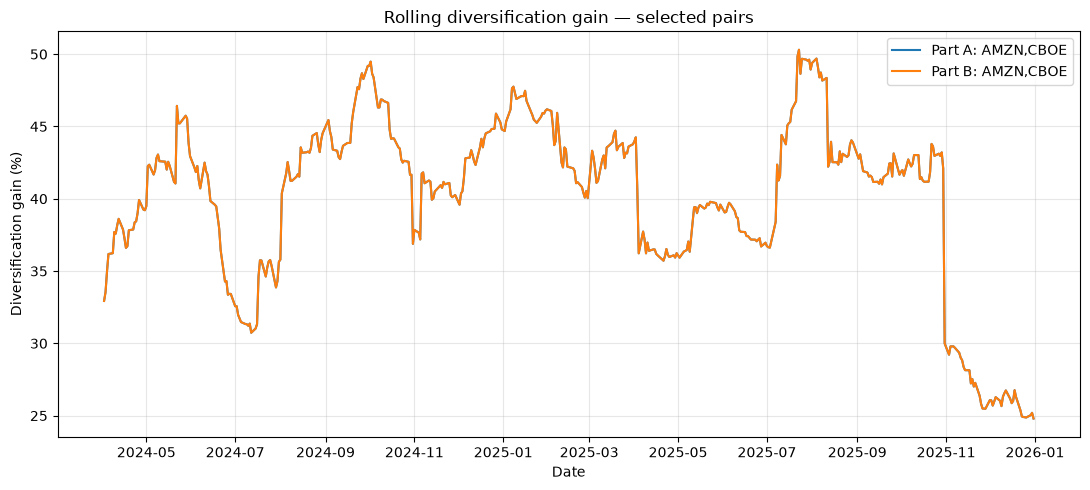

In [7]:
# Plot rolling diversification gains using the same calendar as the search.
fig, ax = plt.subplots(figsize=(11, 5))
for label, winner in [("Part A", part_a), ("Part B", part_b)]:
    stock1, stock2 = winner["Stock 1"], winner["Stock 2"]
    r1, r2 = log_returns[stock1], log_returns[stock2]
    portfolio = (r1 + r2) / 2
    sd1, sd2 = r1.rolling(WINDOW).std(), r2.rolling(WINDOW).std()
    sdp = portfolio.rolling(WINDOW).std()
    dg = 1 - sdp / ((sd1 + sd2) / 2)
    tickers = ",".join(sorted([stock1.replace("-", "."), stock2.replace("-", ".")]))
    ax.plot(dg.index, 100 * dg, label=f"{label}: {tickers}")

ax.set(title="Rolling diversification gain — selected pairs", xlabel="Date", ylabel="Diversification gain (%)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Solution 8 — Show the top 20 pairs

In [8]:
# Display the 20 best pairs for each part, in Wikipedia's ticker format.
for label, subset in [("PART A", statistics), ("PART B", qualifying)]:
    print(f"\n{label} — TOP 20")
    for rank, (_, row) in enumerate(subset.head(20).iterrows(), start=1):
        tickers = sorted([row["Stock 1"].replace("-", "."), row["Stock 2"].replace("-", ".")])
        print(f"{rank:2d}. {','.join(tickers):15s} Score: {row['Score']:.4%}")


PART A — TOP 20
 1. AMZN,CBOE       Score: 37.2322%
 2. CBOE,GOOG       Score: 35.1362%
 3. CBOE,HUBB       Score: 34.9998%
 4. CBOE,MSFT       Score: 34.9393%
 5. CBOE,GOOGL      Score: 34.7866%
 6. AMZN,ED         Score: 34.6519%
 7. CBOE,ETN        Score: 34.3610%
 8. CBOE,NTAP       Score: 33.6317%
 9. CAT,CBOE        Score: 33.5684%
10. CBOE,FTV        Score: 33.4751%
11. CBOE,TRMB       Score: 33.3690%
12. CBOE,META       Score: 33.3545%
13. CBOE,WAB        Score: 33.2360%
14. CBOE,TEL        Score: 33.0196%
15. CBOE,PH         Score: 33.0120%
16. AMT,GOOGL       Score: 33.0027%
17. CBOE,EMR        Score: 32.9716%
18. CBOE,DOV        Score: 32.9535%
19. CBOE,QCOM       Score: 32.9463%
20. ED,MSFT         Score: 32.9344%

PART B — TOP 20
 1. AMZN,CBOE       Score: 37.2322%
 2. CBOE,GOOG       Score: 35.1362%
 3. CBOE,GOOGL      Score: 34.7866%
 4. CAT,CBOE        Score: 33.5684%
 5. CBOE,TRMB       Score: 33.3690%
 6. CBOE,META       Score: 33.3545%
 7. CBOE,WAB        Score: 33.